# Kalman Filter Tuning

This notebook tunes the Kalman Filter parameters.

#### Wheel Speed conversion:

First we redid the TP from week 8 that determines the speed of the thymio in mm/sec based on measurements of the speed thymio measures. We found the following conversion factor:
$$v_{mm/sec} = v_{thymio}\cdot 0.292$$

Later when running experiments we discovered, that our thymio robot consistently drifts to the right side when we set a constant equal speed command for both wheels. For the Kalman filter we have to assume gaussian noise without any bias. Usually in an EKF setting we would augment the state with there bias terms in order to have a closer to gaussian setting. However due to time constraints a static correction in the conversion factor was chosen, which allows an approximate correction of this issue. The following factors were used:
$$\gamma_l, \gamma_r = 0.292, 0.288$$
They proved to be accurate in comparative measurements.

#### Wheel speed measurement noise:

The next step is to estimate the covariance of the noise in wheel speeds. In a first step we tried to implement a Kalman filter that directly uses speed measurements of the left and right wheels as model inputs and then uses the Jacobian of the prediction function with respect to these inputs ($F_u$) to project the wheel speed variances to the state space. The advantage of this approach is that we can directly measure the speed variances of the left and right wheel and we can assume them to be independent (no off-diagonal terms) because they come from two different motors.
$$Q_{wheels} = \begin{bmatrix}\sigma_l^2 & 0 \\ 0 & \sigma_r^2\end{bmatrix} \qquad Q_{ss} = F_u Q_{wheels} F_u^T$$
However this approach turned out to not work reliably and not creating any cumulative variance on the heading estimate of the EKF for a reason we could not determine. We thus decided to estimate $Q_{ss}$, the covariance matrix directly in the state space, by manually upper-bounding $F_u$ which gives us an upper bound on the variances in the state space.

Given that the model is:
$$\begin{split}
x^+ &= x + v_{lin}\cdot\cos(\theta)\cdot dt \\
y^+ &= y + v_{lin}\cdot\sin(\theta)\cdot dt \\
\theta^+ &= \theta + v_{ang}\cdot dt
\end{split}$$
Where:
$$v_{lin} = \frac{v_r + v_l}{2}\qquad v_{ang} = \frac{v_r - v_l}{b}$$
with $b$ the wheel base of the robot that was measured as 94 mm. We thus obtain:
$$F_u = \begin{bmatrix}
\frac{1}{2}\cos(\theta)\cdot dt & \frac{1}{2}\cos(\theta)\cdot dt \\
\frac{1}{2}\sin(\theta)\cdot dt & \frac{1}{2}\sin(\theta)\cdot dt \\
\frac{dt}{b} & -\frac{dt}{b}
\end{bmatrix} \leq \frac{1}{2} \begin{bmatrix}
dt & dt \\
dt & dt \\
\frac{2\cdot dt}{b} & -\frac{2\cdot dt}{b}
\end{bmatrix}$$

Using a time-step of $0.1$ sec we can now convert our wheel speed variances to a state-space covariance. This is done in the code below.


In [20]:
%reload_ext autoreload
%autoreload 2

import sys
import numpy as np
import matplotlib.pyplot as plt
import time
import polars as pl
from tqdm import tqdm
import cv2

sys.path.append('../')

from src.thymio import ThymioClient
from src.vision import Camera, Vision

In [2]:
# function to drive robot and sample speeds

def sample_constant_speed(thymio, v_right, v_left, duration_sec, dt_sec, warmup_sec=1.0):

    # Let 1 sec to reach speed
    print("Warmup to stabilize speed...")
    thymio.set_motors(v_left, v_right)
    time.sleep(warmup_sec)

    # Sample data
    start = time.time()
    last_meas = start

    samples = int(duration_sec / dt_sec)
    pbar = tqdm(total=samples, desc="Sampling", unit="samples")

    times = []
    cmd_r = []
    cmd_l = []
    meas_r = []
    meas_l = []

    while True:
        thymio.wait(dt_sec)
        
        current_time = time.time()

        # take sample
        _, v_l, v_r, _ = thymio.get_measurements()

        times.append(current_time - start)
        cmd_r.append(v_right)
        cmd_l.append(v_left)
        meas_r.append(v_r)
        meas_l.append(v_l)

        pbar.update()

        if current_time - start > duration_sec + dt_sec: # allow last sample
            thymio.set_motors(0, 0)
            break

    pbar.close()
            
    # Initialize data frame
    samples = pl.DataFrame({
        "time": times,
        "cmd_r": cmd_r,
        "cmd_l": cmd_l,
        "meas_r": meas_r,
        "meas_l": meas_l,
    })

    return samples
    

In [3]:
experiment = pl.DataFrame()

speeds = [50, 75, 100, 150, 200]
samples_per_speed = 100
sample_period = 0.2 # sec
duration = samples_per_speed*sample_period # sec
warmup = 2.0 # sec

thymio = ThymioClient()

for speed in speeds:
    print(f"Sample at speed {speed}:")
    samples = sample_constant_speed(thymio, speed, speed, duration, sample_period, warmup)
    print("Wait for 5 sec to replace thymio...")
    time.sleep(5)

    experiment = pl.concat((experiment, samples))

thymio.close()

Client created and connected to Thymio.
Sample at speed 50:
Warmup to stabilize speed...


Sampling: 100%|██████████| 100/100 [00:20<00:00,  4.90samples/s]


Wait for 5 sec to replace thymio...
Sample at speed 75:
Warmup to stabilize speed...


Sampling: 101samples [00:20,  4.93samples/s]                    


Wait for 5 sec to replace thymio...
Sample at speed 100:
Warmup to stabilize speed...


Sampling: 100%|██████████| 100/100 [00:20<00:00,  4.92samples/s]


Wait for 5 sec to replace thymio...
Sample at speed 150:
Warmup to stabilize speed...


Sampling: 100%|██████████| 100/100 [00:20<00:00,  4.93samples/s]


Wait for 5 sec to replace thymio...
Sample at speed 200:
Warmup to stabilize speed...


Sampling: 100%|██████████| 100/100 [00:20<00:00,  4.93samples/s]


Wait for 5 sec to replace thymio...
Stopping Thymio client and unlocking robot.


In [8]:
experiment

time,cmd_r,cmd_l,meas_r,meas_l
f64,i64,i64,i64,i64
0.210186,50,50,50,51
0.514784,50,50,49,50
0.716632,50,50,49,49
0.918604,50,50,50,49
1.120368,50,50,49,47
…,…,…,…,…
19.392683,200,200,201,198
19.594738,200,200,205,210
19.797297,200,200,201,194


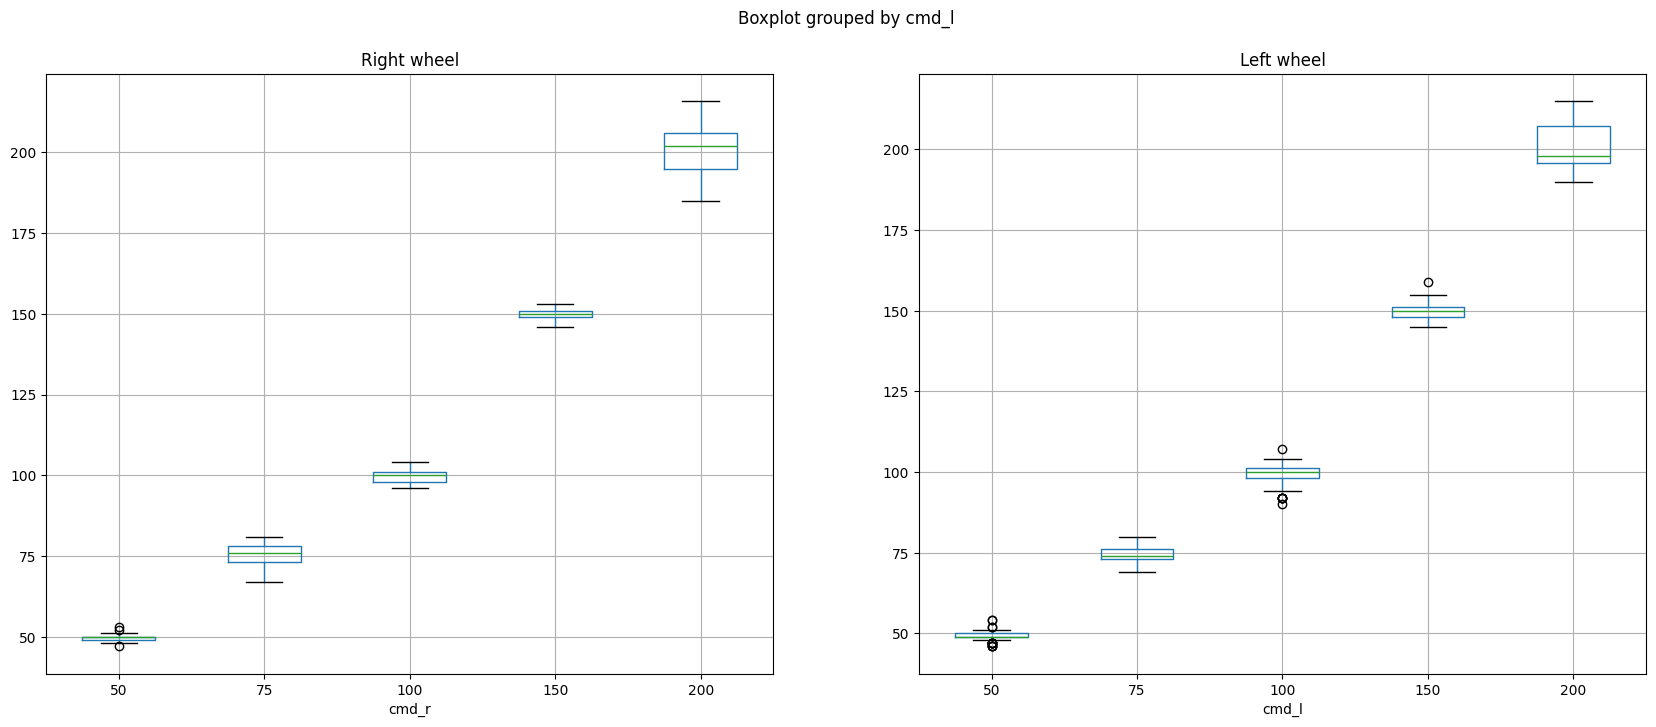

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(20,8))
experiment.to_pandas().boxplot(by="cmd_r", column="meas_r", ax=axs[0])
experiment.to_pandas().boxplot(by="cmd_l", column="meas_l", ax=axs[1])
axs[0].set_title("Right wheel")
axs[1].set_title("Left wheel")
plt.show()

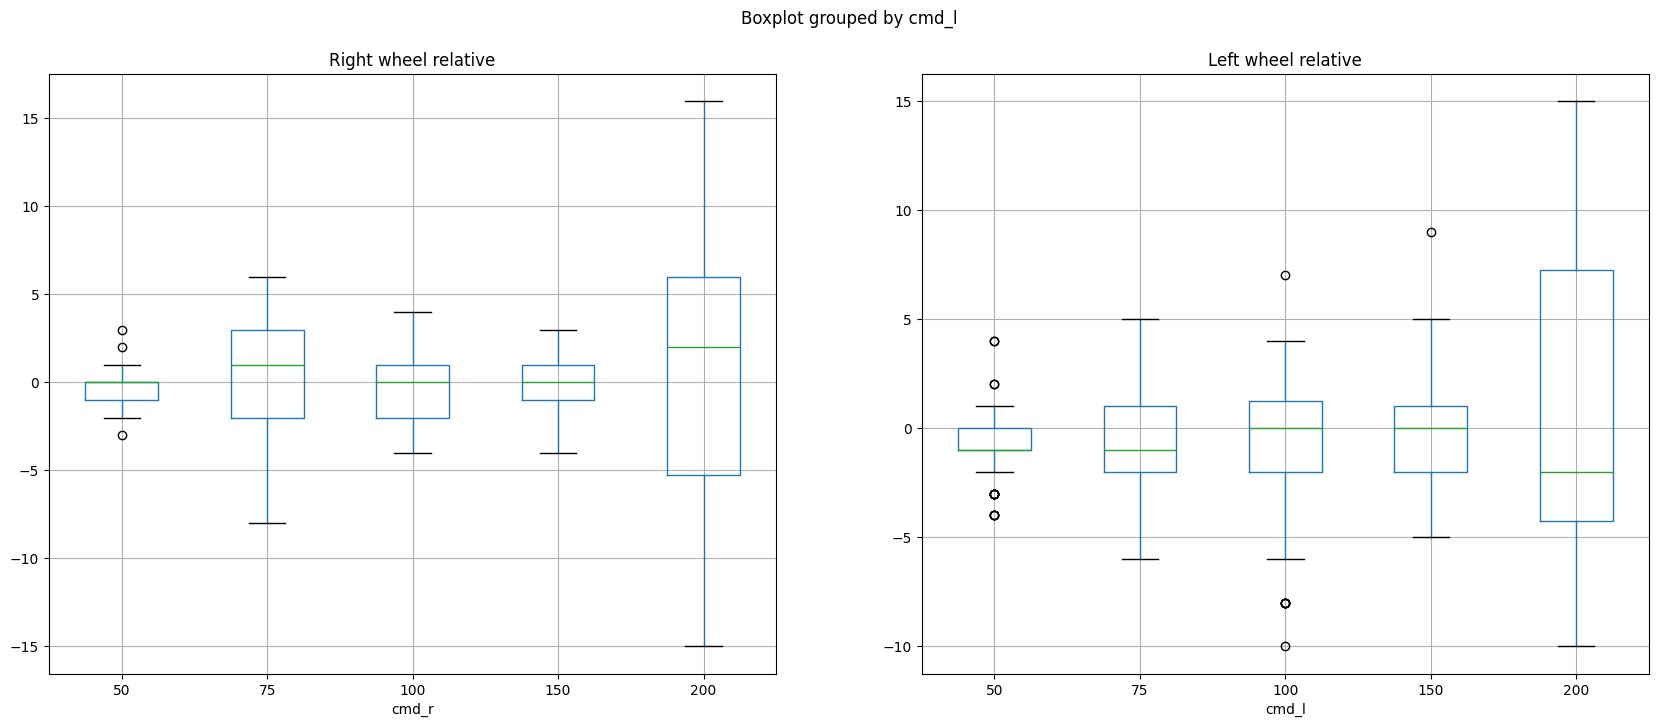

In [10]:
diff = experiment.with_columns(
    diff_r = pl.col("meas_r") - pl.col("cmd_r"),
    diff_l = pl.col("meas_l") - pl.col("cmd_l")
)

fig, axs = plt.subplots(1, 2, figsize=(20,8))
diff.to_pandas().boxplot(by="cmd_r", column="diff_r", ax=axs[0])
diff.to_pandas().boxplot(by="cmd_l", column="diff_l", ax=axs[1])
axs[0].set_title("Right wheel relative")
axs[1].set_title("Left wheel relative")
plt.show()

In [16]:
# Calculate variance of the errors
var_r = diff.select(pl.col("diff_r").var()).to_numpy()[0,0]
var_l = diff.select(pl.col("diff_l").var()).to_numpy()[0,0]

# Convert to ekf units
var_r_mm = var_r * 0.288
var_l_mm = var_l * 0.292

print(f"Variance of right wheel error: {var_r_mm}")
print(f"Variance of left wheel error: {var_l_mm}")

# Convert to state-space:
dt = 0.1 # sec
ROBOT_WIDTH_MM = 94 # mm
Q_wheels = np.diag([var_r_mm, var_l_mm])
F_u = np.array([[dt, dt], [dt, dt], [dt/ROBOT_WIDTH_MM, -dt/ROBOT_WIDTH_MM]])

Q_state = F_u @ Q_wheels @ F_u.T
print("Process noise covariance Q:\n", Q_state)

Variance of right wheel error: 3.611839616766466
Variance of left wheel error: 3.9842181876247498
Process noise covariance Q:
 [[ 7.59605780e-02  7.59605780e-02 -3.96147416e-05]
 [ 7.59605780e-02  7.59605780e-02 -3.96147416e-05]
 [-3.96147416e-05 -3.96147416e-05  8.59671549e-06]]


This gives us a first estimative baseline for the variance of the predicted state. We can also see on the plots that the wheel speed variance increases with the speed which we could take into account to make our model more precise. This was not done due to time constraints. The results proved to work better in reality when we removed the diagonal terms, it is not entirely clear to us, why this effect exists. Thus we had to tune these values quite a bit by hand in order to have reasonable estimates.

**Critique:**

The results of this part are not entirely satisfying since there is a mismatch between the theoretical deviations and practical results here. In the end the tuning of the process covariances was done by running the ekf prediction without the update and comparing with the camera results and thus deriving the covariances directly in the state space. This was done very close to the deadline and there was no time for a thorough mathematical review but the values correspond reasonably well to what we observe in reality. 

#### Camera measurement noise:

The update of the EKF uses camera measurements. We observed that they are generally very accurate and they don't fluctuate very much which allows us to assign them a rather small variance. Furthermore we assume the camera errors in the different axes of the state space to be independent in order to make the measurement noise covariance $R$ a diagonal matrix. In practice this is not entirely true since the heading and the position are infered from the same four points (corners of the aruco code) and thus error on one of these points propagates to both the position and the angle estimates. However this cross-dependancy is hard to measure and given that the camera measurements globally proved to be very reliable, we decided to neglect it. 

The camera error mainly consists of single pixel errors which we can convert to the EKF units. Due to the distortion pixel errors are more likely to occur further away from the camera (i.e. on the top edge of the arena) which is why we measure the variances in this area. Errors were artificially provoqued by changing the lighting.

The real error of the measurements will be larger due to motion blur and small timing offsets. These factors are hard to reproduce since the camera is our most reliable tool to localize the robot. One option would be to program a trajectory and to measure at different time-steps where the robot actually is and where the camera thinks it is. This however is a time-consuming process which is why we decided to just add an uncertainty facotor of $\alpha = 7$ to the statically measured variance of the camera estimates.

The following code measures the variance of the camera state estiates and produces the diagonal covariance matrix including the correction factor: 

Camera with ID 4 opened successfully.
Camera thread launched
Camera fps: 30.0
Detected markers: {69: (57.0, 375.0), 23: (566.0, 376.0), 30: (533.0, 56.0), 42: (88.0, 52.0)}
Map size in pixels: width = 445.0 , height = 320.0
Pixels per cm: 4.684210526315789


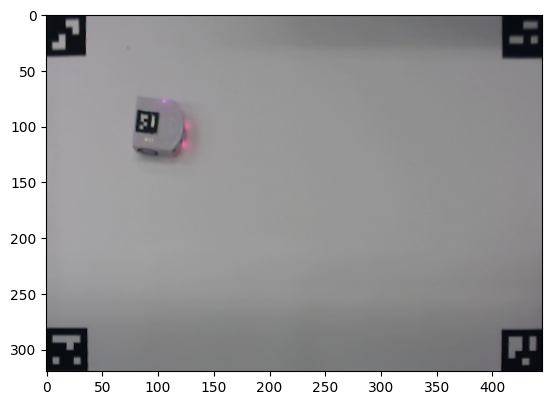

In [21]:
cam_id = 4
cam = Camera(cam_id)
vision = Vision()

# Let Camera adjust
cv2.namedWindow("output", cv2.WINDOW_NORMAL)

while True:

    ret, frame = cam.get_frame()

    if not ret:
        print("Error: Could not read frame.")
        break

    cv2.imshow("output", frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cv2.destroyAllWindows()

# Print camera stats:
print("Camera fps:", cam.cap.get(cv2.CAP_PROP_FPS))

# Initialize vision
test_frame = vision.setup(frame)
test_frame = cv2.cvtColor(test_frame, cv2.COLOR_BGR2RGB)

plt.imshow(test_frame)
plt.show()

In [24]:
# Take 300 samples at five different positions and orientations

positions = 6
samples_per_position = 300

variances = []
samples_all = []

for pos in range(positions):
    
    samples = []
    
    for i in tqdm(range(samples_per_position), desc=f"Position {pos}", unit="samples"):
        ret, frame = cam.get_frame()
        
        if not ret:
            print("Error: Could not read frame.")
            break

        found, pose, _ = vision.localize_robot(frame)
        if found is True:
            samples.append(pose)

        # wait 0.05 sec -> 20 Hz
        time.sleep(0.05)
    
    samples = np.array(samples)
    samples_all.append(samples)
    
    print(f"Position {pos}:")
    print("Samples collected:", samples.shape[0])
    print("Mean:", np.mean(samples, axis=0))
    print("Variance:", np.var(samples, axis=0))
    variances.append(np.var(samples, axis=0))

    print("Change position and press Enter to continue...")
    input()

    print()

Position 0: 100%|██████████| 300/300 [00:18<00:00, 16.25samples/s]

Position 0:
Samples collected: 255
Mean: [64.54509804 59.44215686  0.08081175]
Variance: [0.0558093  0.02876201 0.00113702]
Change position and press Enter to continue...


Position 1: 100%|██████████| 300/300 [00:18<00:00, 16.23samples/s]

Position 1:
Samples collected: 300
Mean: [138.52166667  56.20333333   1.180014  ]
Variance: [0.02411389 0.03157222 0.00030888]
Change position and press Enter to continue...


Position 2: 100%|██████████| 300/300 [00:18<00:00, 16.26samples/s]

Position 2:
Samples collected: 153
Mean: [258.27777778  55.44444444   2.32214611]
Variance: [0.23248003 0.08596587 0.00323168]
Change position and press Enter to continue...


... (2 outputs left out)

Position 4: 100%|██████████| 300/300 [00:18<00:00, 16.29samples/s]

Position 4:
Samples collected: 207
Mean: [273.75483092 127.75362319  -0.73357477]
Variance: [0.06700565 0.03954001 0.00121291]
Change position and press Enter to continue...


Position 5: 100%|██████████| 300/300 [00:18<00:00, 16.30samples/s]

Position 5:
Samples collected: 299
Mean: [143.92725753 119.14966555   0.69845861]
Variance: [0.05929883 0.09904671 0.00054593]
Change position and press Enter to continue...


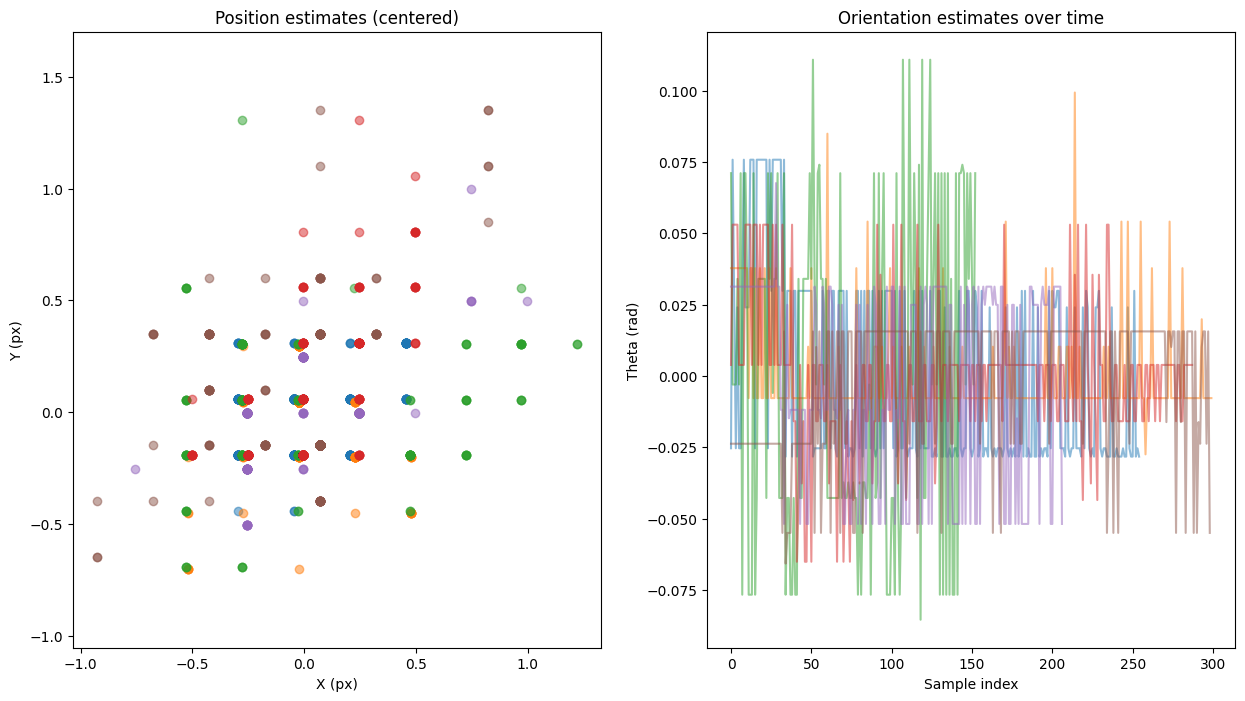

In [26]:
# Scatter the results for all positions

# Remove means from samples
samples_centered = []
for samples in samples_all:
    mean = np.mean(samples, axis=0)
    samples_centered.append(samples - mean)

plt.figure(figsize=(15,8))
plt.subplot(1, 2, 1)
for samples in samples_centered:
    plt.scatter(samples[:,0], samples[:,1], alpha=0.5)
plt.title("Position estimates (centered)")
plt.xlabel("X (px)")
plt.ylabel("Y (px)")
plt.axis('equal')

plt.subplot(1, 2, 2)
for samples in samples_centered:
    plt.plot(samples[:,2], alpha=0.5)
plt.title("Orientation estimates over time")
plt.xlabel("Sample index")
plt.ylabel("Theta (rad)")
plt.show()


In [34]:
# Calculate variance matrix for EKF R matrix
variances = np.array(variances)

px_per_mm = vision.pixels_per_cm / 10.0  # pixels per mm
print("Pixels per mm:", px_per_mm)

variances_mm = np.zeros_like(variances)
variances_mm[:, 0:2] = variances[:,0:2] / (px_per_mm**2)  # convert position variances to mm
variances_mm[:, 2] = variances[:,2]  # orientation variance in rad

mean_variance_scaled = np.mean(variances_mm, axis=0) * 7.0  # correction factor for motion blur etc.

print("Mean variances over all positions:", mean_variance_scaled)
R_ekf = np.diag(mean_variance_scaled)  # apply correction factor
print("\nEKF Measurement noise covariance R:\n", R_ekf)

Pixels per mm: 0.46842105263157896
Mean variances over all positions: [2.57259157 1.95194594 0.00818785]

EKF Measurement noise covariance R:
 [[2.57259157 0.         0.        ]
 [0.         1.95194594 0.        ]
 [0.         0.         0.00818785]]


In [35]:
cam.stop()

Camera with ID 4 released, thread stopped
